# 11 — Neural Network Decision Threshold Experiment

## Objective

Investigate the effect of varying the decision probability threshold on the performance of the previously trained class-balanced neural network for pork rasher packaging inspection.

The original neural network uses a default classification threshold of 0.5. This experiment will evaluate alternative thresholds to determine how they influence the classification of packages as PASS or FAIL.

## Methodology

The same trained neural network, six whole-image RGB features, and validation dataset from Notebook 10 will be used.

The network's predicted probability of PASS will be compared against a range of decision thresholds. A package is classified as PASS when its predicted probability meets or exceeds the selected threshold; otherwise, it is classified as FAIL.

For each threshold, the following metrics will be calculated:

- Overall classification accuracy
- Balanced accuracy
- Macro F1-score
- Number of false PASS predictions
- Number of false FAIL predictions

The results will be visualised to investigate the relationship between decision threshold and classification performance.

## Expected Outcome

Identify how decision threshold selection affects the trade-off between incorrectly accepting defective packages and incorrectly rejecting acceptable packages.

No retraining will be performed in this experiment. Only the final classification decision rule will be modified.

### Verify environment and import packages
Confirm the active Python interpreter and load imaging, plotting, and evaluation libraries.

In [255]:
# Display the interpreter used by this notebook for environment troubleshooting.
import sys
print(sys.executable)

c:\Users\bengr\OneDrive - Monash University\Desktop\Uni\3001 Numerical Methods and Machine Learning\Pork Rasher Inspection\notebooks\.venv\Scripts\python.exe


In [256]:
# Load image-processing, table, plotting, annotation, and evaluation packages.
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### Locate and read validation annotations
Point to the validation folder already supplied with the dataset; no new split is made.

In [257]:
import joblib
from pathlib import Path

# Define the project root directory.
PROJECT_ROOT = Path("..")

# Define the validation image directory.
VALID_IMAGE_DIR = PROJECT_ROOT / "data" / "raw" / "valid"

# Define the location of the COCO annotations.
VALID_ANNOTATIONS = (
    VALID_IMAGE_DIR / "_annotations.coco.json"
)

# Load the previously trained class-balanced neural network.
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "baseline_neural_network.joblib"
)

model = joblib.load(MODEL_PATH)

# Confirm that the correct model was loaded.
print("Loaded model:", MODEL_PATH)
print(model)

Loaded model: ..\models\baseline_neural_network.joblib
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 MLPClassifier(alpha=0.01, hidden_layer_sizes=(16, 8),
                               max_iter=1000, random_state=67))])


In [258]:
# Parse image metadata and defect annotations from the COCO JSON file.
with open(VALID_ANNOTATIONS, "r") as f:
    coco_data = json.load(f)

### Construct ground-truth validation labels
Find annotated images and apply the existing annotation-present → FAIL rule.

In [259]:
# Build a set of image IDs with at least one defect annotation.
# Set membership avoids scanning every annotation for each image.

annotated_image_ids = {
    annotation["image_id"]
    for annotation in coco_data["annotations"]
}

In [260]:
# Derive a single PASS/FAIL label for each validation image.
# This assumes unannotated images represent acceptable packages.
validation_labels = []

for image in coco_data["images"]:

    image_id = image["id"]
    filename = image["file_name"]

    if image_id in annotated_image_ids:
        label = "FAIL"
    else:
        label = "PASS"

    validation_labels.append({
        "filename": filename,
        "label": label
    })

valid_labels_df = pd.DataFrame(validation_labels)

In [261]:
# Check class counts to understand validation-set imbalance.
print(valid_labels_df["label"].value_counts())
print("\nTotal validation images:", len(valid_labels_df))

label
FAIL    106
PASS     14
Name: count, dtype: int64

Total validation images: 120


### Extract consistent RGB features
Use the same feature definitions as Notebook 04 for every validation image.

In [262]:
def extract_rgb_features(image_path):
    """Calculate six image-level RGB statistics for a validation image.

    Parameters
    ----------
    image_path : str or pathlib.Path
        Location of the image to analyse.

    Returns
    -------
    dict
        Mean and standard deviation for each RGB colour channel.

    Raises
    ------
    ValueError
        If OpenCV cannot load the requested image.

    Notes
    -----
    OpenCV reads images in BGR order, so the loaded pixels are converted
    to RGB before calculating features to match the training feature set.
    """

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not load image: {image_path}")

    # OpenCV loads images as BGR
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    red = image_rgb[:, :, 0]
    green = image_rgb[:, :, 1]
    blue = image_rgb[:, :, 2]

    return {
        "mean_red": np.mean(red),
        "mean_green": np.mean(green),
        "mean_blue": np.mean(blue),
        "std_red": np.std(red),
        "std_green": np.std(green),
        "std_blue": np.std(blue)
    }

In [263]:
# Compute RGB features for every labelled validation image.
# The image-level feature definitions must match the training notebook.
validation_rows = []

for _, row in valid_labels_df.iterrows():

    image_path = VALID_IMAGE_DIR / row["filename"]

    features = extract_rgb_features(image_path)

    features["filename"] = row["filename"]
    features["label"] = row["label"]

    validation_rows.append(features)

valid_features_df = pd.DataFrame(validation_rows)

valid_features_df.head()

,mean_red,mean_green,mean_blue,std_red,std_green,std_blue,filename,label
0,49.399792,47.326512,48.664519,42.643538,34.142742,35.183197,frame_with_red_8649_jpg.rf.a4d923187143603a280...,FAIL
1,45.959835,43.577181,44.300898,37.444479,28.650479,29.526516,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,PASS
2,50.669578,47.752994,49.097765,42.503044,32.754078,33.678070,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,FAIL
3,56.327726,52.025087,53.961443,48.824981,36.230730,37.636808,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,FAIL
4,58.202109,53.662752,54.142541,55.981233,43.544077,43.061124,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,FAIL


### Assemble model inputs and load the neural network
Predictors must have the same names and ordering as during training.

In [264]:
# Use the exact same six predictor columns and their training-time order.
#Seperate Features from correct answers
feature_columns = [
    "mean_red",
    "mean_green",
    "mean_blue",
    "std_red",
    "std_green",
    "std_blue"
]

X_valid = valid_features_df[feature_columns]
y_valid = valid_features_df["label"]

In [265]:
# Import model deserialisation utilities.
#Loading model
import joblib
from pathlib import Path

In [266]:
# Define the project root directory.
PROJECT_ROOT = Path("..")

# Specify the saved neural network model from Notebook 09.
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "baseline_neural_network.joblib"
)

# Load the trained neural network pipeline.
# This should include the fitted StandardScaler and MLPClassifier.
model = joblib.load(MODEL_PATH)

# Display the loaded pipeline to verify the correct model was loaded.
print(model)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 MLPClassifier(alpha=0.01, hidden_layer_sizes=(16, 8),
                               max_iter=1000, random_state=67))])


### Predict and inspect individual classifications
Compare each prediction with the annotation-derived label.

In [267]:
# Obtain the predicted class probabilities for each image.
predicted_probabilities = model.predict_proba(X_valid)

# Identify which column represents the PASS class.
pass_index = list(model.classes_).index("PASS")

# Extract the predicted probability that each image is PASS.
pass_probabilities = predicted_probabilities[:, pass_index]

# Define the minimum probability required to classify an image as PASS.
PASS_THRESHOLD = 0.45

# Assign PASS if its predicted probability exceeds the threshold.
# Otherwise classify the image as FAIL.
y_pred = np.where(
    pass_probabilities >= PASS_THRESHOLD,
    "PASS",
    "FAIL"
)

print(f"Decision threshold: {PASS_THRESHOLD}")

Decision threshold: 0.45


In [268]:
# Compare predictions to reference labels for per-image error analysis.
results_df = valid_features_df[
    ["filename", "label"]
].copy()

results_df["prediction"] = y_pred

results_df["correct"] = (
    results_df["label"] == results_df["prediction"]
)
#Printing short results table
results_df.head(20)

,filename,label,prediction,correct
0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,FAIL,FAIL,True
1,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,PASS,PASS,True
2,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,FAIL,FAIL,True
3,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,FAIL,FAIL,True
4,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,FAIL,FAIL,True
5,frame_with_red_531_jpg.rf.d1bf4eab747883d5e9fa...,FAIL,FAIL,True
6,frame_with_red_1308_jpg.rf.4fe453ba69054077d74...,PASS,PASS,True
7,frame_with_red_6194_jpg.rf.6c5b8fe814fbf13689b...,FAIL,FAIL,True
8,frame_with_red_9311_jpg.rf.42e8694a15dd5e3b34e...,FAIL,PASS,False
9,frame_with_red_2617_jpg.rf.a1009fb1133a89370a9...,FAIL,FAIL,True


### Evaluate classification performance
Review overall accuracy and class-level metrics; class imbalance makes accuracy alone insufficient.

In [269]:
# Calculate overall classification accuracy.
accuracy = accuracy_score(y_valid, y_pred)

# Calculate balanced accuracy.
# This averages the recall of PASS and FAIL, giving equal
# importance to both classes regardless of their frequencies.
balanced_accuracy = balanced_accuracy_score(y_valid, y_pred)

# Calculate macro F1-score.
# This calculates F1 separately for PASS and FAIL, then
# averages the results without weighting by class frequency.
macro_f1 = f1_score(
    y_valid,
    y_pred,
    average="macro"
)

# Print the evaluation results.
print(f"Validation accuracy: {accuracy:.2%}")
print(f"Balanced accuracy: {balanced_accuracy:.2%}")
print(f"Macro F1-score: {macro_f1:.3f}")

Validation accuracy: 78.33%
Balanced accuracy: 75.34%
Macro F1-score: 0.650


In [270]:
# Report precision, recall, F1, and support for each class.
from sklearn.metrics import classification_report

print(
    classification_report(
        y_valid,
        y_pred,
        digits=3
    )
)

              precision    recall  f1-score   support

        FAIL      0.955     0.792     0.866       106
        PASS      0.312     0.714     0.435        14

    accuracy                          0.783       120
   macro avg      0.634     0.753     0.650       120
weighted avg      0.880     0.783     0.816       120



### Confusion matrix
Display how actual FAIL and PASS images are classified by the model.

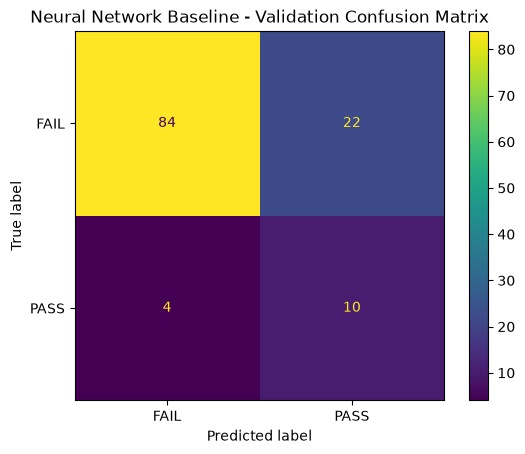

In [271]:
# Organise prediction outcomes by actual and predicted class.
#Generate confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_valid,
    y_pred,
    labels=["FAIL", "PASS"]
)

# Create a confusion matrix visualisation.
# Use a descriptive variable name to avoid overwriting display().
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["FAIL", "PASS"]
)

# Plot the confusion matrix.
cm_display.plot()

plt.title("Neural Network Baseline - Validation Confusion Matrix")
plt.show()

In [272]:
import numpy as np

# Identify the position of the FAIL class.
fail_index = list(model.classes_).index("FAIL")

# Obtain the predicted probability of FAIL for each image.
fail_probabilities = model.predict_proba(X_valid)[:, fail_index]

# Summarise the model's predicted FAIL probabilities.
print("Minimum:", np.min(fail_probabilities))
print("Mean:", np.mean(fail_probabilities))
print("Maximum:", np.max(fail_probabilities))

Minimum: 0.25735019534844883
Mean: 0.6751814701581196
Maximum: 0.9371782108539932


## Investigating Multiple Decision Thresholds

To investigate the sensitivity of the neural network's performance to the classification decision threshold, a range of PASS probability thresholds will be evaluated.

The trained neural network remains unchanged throughout this experiment. For each threshold, predictions will be generated using the previously calculated PASS probabilities.

The following performance metrics will be compared:

- Classification accuracy
- Balanced accuracy
- Macro F1-score
- False PASS predictions (defective packaging incorrectly accepted)
- False FAIL predictions (acceptable packaging incorrectly rejected)

In [273]:
# Define the probability thresholds to investigate.
thresholds = np.arange(0.05, 1.00, 0.05)

# Create an empty list to store the performance metrics.
threshold_results = []

# Evaluate the neural network at each decision threshold.
for threshold in thresholds:

    # Generate PASS/FAIL predictions at the current threshold.
    predictions = np.where(
        pass_probabilities >= threshold,
        "PASS",
        "FAIL"
    )

    # Calculate the confusion matrix.
    cm = confusion_matrix(
        y_valid,
        predictions,
        labels=["FAIL", "PASS"]
    )

    # Extract the number of each classification outcome.
    true_fail = cm[0, 0]
    false_pass = cm[0, 1]
    false_fail = cm[1, 0]
    true_pass = cm[1, 1]

    # Calculate the classification metrics.
    accuracy = accuracy_score(y_valid, predictions)

    balanced_acc = balanced_accuracy_score(
        y_valid, predictions
    )

    macro_f1 = f1_score(
        y_valid,
        predictions,
        average="macro",
        labels=["FAIL", "PASS"],
        zero_division=0
    )

    # Store the results for the current threshold.
    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_acc,
        "Macro F1": macro_f1,
        "False PASS": false_pass,
        "False FAIL": false_fail
    })

# Convert results into a DataFrame.
threshold_df = pd.DataFrame(threshold_results)

# Display the results.
display(threshold_df)

,Threshold,Accuracy,Balanced Accuracy,Macro F1,False PASS,False FAIL
0,0.05,0.116667,0.500000,0.104478,106,0
1,0.10,0.141667,0.514151,0.134393,103,0
2,0.15,0.258333,0.580189,0.257870,89,0
3,0.20,0.441667,0.621968,0.407036,65,2
4,0.25,0.500000,0.654987,0.450549,58,2
5,0.30,0.600000,0.711590,0.523810,46,2
6,0.35,0.675000,0.754043,0.580307,37,2
7,0.40,0.741667,0.760782,0.624659,28,3
8,0.45,0.783333,0.753369,0.650381,22,4
9,0.50,0.800000,0.638814,0.607843,16,8


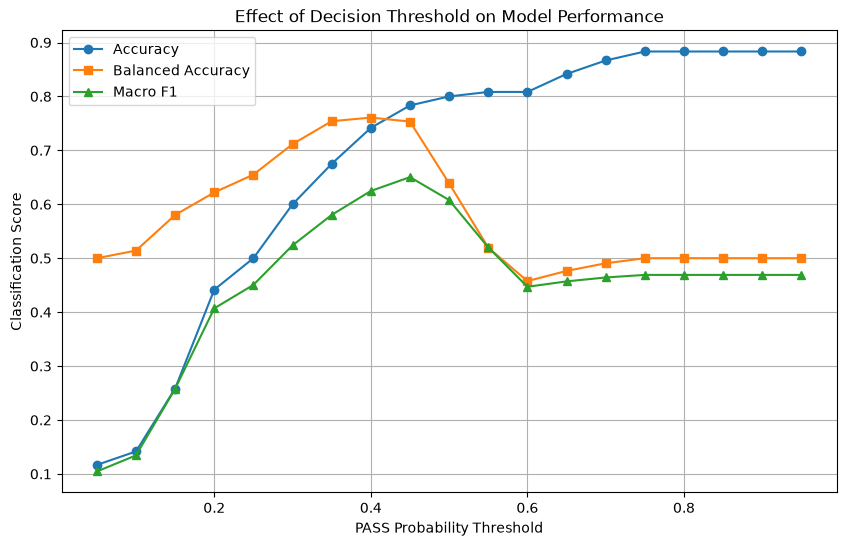

In [274]:
# Create a figure comparing classification performance.
plt.figure(figsize=(10, 6))

# Plot accuracy against decision threshold.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

# Plot balanced accuracy against decision threshold.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Balanced Accuracy"],
    marker="s",
    label="Balanced Accuracy"
)

# Plot macro F1-score against decision threshold.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Macro F1"],
    marker="^",
    label="Macro F1"
)

# Label the axes and graph.
plt.xlabel("PASS Probability Threshold")
plt.ylabel("Classification Score")
plt.title("Effect of Decision Threshold on Model Performance")

# Improve readability.
plt.legend()
plt.grid(True)

plt.show()

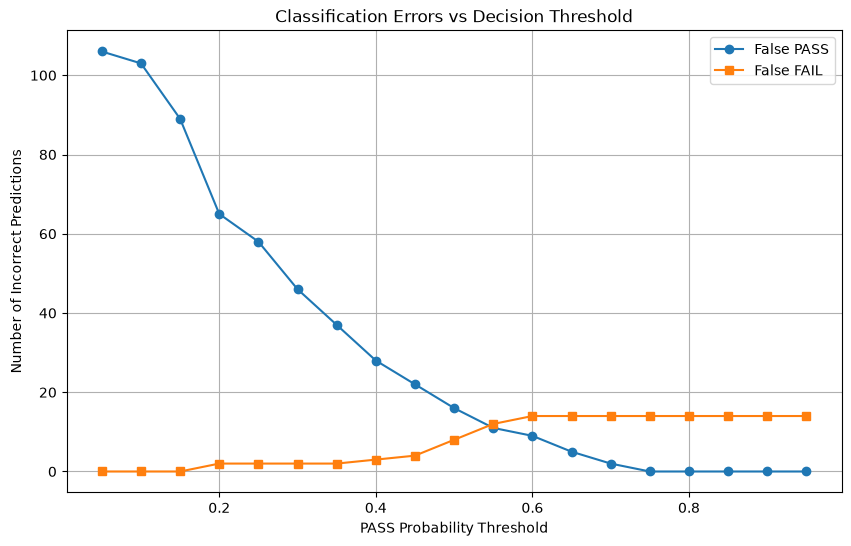

In [275]:
# Compare how different thresholds affect classification errors.
plt.figure(figsize=(10, 6))

# Defective packages incorrectly classified as acceptable.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["False PASS"],
    marker="o",
    label="False PASS"
)

# Acceptable packages incorrectly classified as defective.
plt.plot(
    threshold_df["Threshold"],
    threshold_df["False FAIL"],
    marker="s",
    label="False FAIL"
)

plt.xlabel("PASS Probability Threshold")
plt.ylabel("Number of Incorrect Predictions")
plt.title("Classification Errors vs Decision Threshold")

plt.legend()
plt.grid(True)

plt.show()

In [276]:
# Find the threshold producing the highest macro F1-score.
best_row = threshold_df.loc[
    threshold_df["Macro F1"].idxmax()
]

print("Best threshold based on Macro F1:")
print(best_row)

Best threshold based on Macro F1:
Threshold             0.450000
Accuracy              0.783333
Balanced Accuracy     0.753369
Macro F1              0.650381
False PASS           22.000000
False FAIL            4.000000
Name: 8, dtype: float64
